## **National Accounts Statistics of India Using Python**
## **Overview**

This project focuses on cleaning, processing, and analysing National Accounts Statistics data using Python. The study identifies missing values, duplicate records, inconsistencies, and data-type issues. Descriptive statistical methods and data visualisation are used to explore economic indicators, compare industries, and understand changes over time. The cleaned dataset will be saved in CSV format for further analysis.







## **Dataset Information**

- **Dataset Name:** National Accounts Statistics of India
- **Source:** https://www.data.gov.in/resource/national-accounts-statistics-data
- **Location:** India
- **Domain:** National Accounts Statistics
- **Time Period:** 1999 to 2025–26
- **Data Frequency:** Annual and Quartely


## **Objectives of the Study**

1. To understand the structure and characteristics of the National Accounts Statistics dataset of India, including its columns, data types, and economic indicators.

2. To clean and preprocess the dataset by identifying and handling missing values, removing duplicate records, correcting inconsistencies, standardizing column names, removing unnecessary columns, and converting data types where necessary.

3. To perform descriptive statistical analysis by calculating measures such as mean, median, and standard deviation for suitable numerical variables and examining economic indicators.

4. To analyse year-wise and quarterly changes in economic indicators, compare economic performance across available industries or sectors, and identify patterns and trends using visualizations created with Matplotlib and Seaborn.

5. To interpret the findings, summarize the major insights, and save the cleaned dataset in CSV format for further analysis and research.

## **Import Data**

In [1]:
# import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# load the dataset

url = "https://raw.githubusercontent.com/poornitha-subramani/National_Account_Statistics_of_India_/main/National_statistics_account.csv"

df = pd.read_csv(url)

## **Initial EDA**

In [3]:
# head
df.head()

,base_year,series,year,indicator,frequency,revision,industry,subindustry,institutional_sector,quarter,current_price,constant_price,unit
0,2011-12,Current,2019-20,Gross Value Added,Annual,Second Revised Estimates,NaN,NaN,Private Non-Financial Corporations,NaN,6.241334e+06,NaN,₹ Crore
1,2011-12,Current,2019-20,Gross Value Added,Annual,Second Revised Estimates,"Agriculture, Livestock, Forestry and Fishing",Livestock,NaN,NaN,9.777301e+05,581449.540055,₹ Crore
2,2011-12,Current,2019-20,Gross Value Added,Annual,Second Revised Estimates,"Agriculture, Livestock, Forestry and Fishing",Forestry and Logging,NaN,NaN,2.606026e+05,164415.522136,₹ Crore
3,2011-12,Current,2019-20,Gross Value Added,Annual,Second Revised Estimates,"Agriculture, Livestock, Forestry and Fishing",Fishing and Aquaculture,NaN,NaN,2.280652e+05,129893.297959,₹ Crore
4,2011-12,Current,2019-20,Gross Value Added,Annual,Second Revised Estimates,Manufacturing,Other Manufactured Goods,NaN,NaN,1.038057e+06,841462.412132,₹ Crore


In [4]:
# size
print(df.shape)

(7836, 13)


In [5]:
# Columns in the dataset
print(df.columns)

Index(['base_year', 'series', 'year', 'indicator', 'frequency', 'revision',
       'industry', 'subindustry', 'institutional_sector', 'quarter',
       'current_price', 'constant_price', 'unit'],
      dtype='object')


In [6]:
# Info of this data
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7836 entries, 0 to 7835
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   base_year             7836 non-null   object 
 1   series                7836 non-null   object 
 2   year                  7836 non-null   object 
 3   indicator             7836 non-null   object 
 4   frequency             7836 non-null   object 
 5   revision              5824 non-null   object 
 6   industry              4958 non-null   object 
 7   subindustry           1759 non-null   object 
 8   institutional_sector  1036 non-null   object 
 9   quarter               2012 non-null   object 
 10  current_price         6926 non-null   float64
 11  constant_price        6873 non-null   float64
 12  unit                  7836 non-null   object 
dtypes: float64(2), object(11)
memory usage: 796.0+ KB
None


In [7]:
df.describe()

,current_price,constant_price
count,6.926000e+03,6.873000e+03
mean,2.197954e+06,1.279091e+06
std,4.871231e+06,3.103633e+06
min,-1.345478e+06,-4.191968e+05
25%,3.424125e+04,9.808441e+00
50%,4.236652e+05,2.164109e+05
75%,1.768831e+06,9.733998e+05
max,3.620479e+07,3.231203e+07


In [8]:
# duplicates value
df.duplicated().sum()

np.int64(0)

In [9]:
# sum of null values
df.isnull().sum()

,0
base_year,0
series,0
year,0
indicator,0
frequency,0
revision,2012
industry,2878
subindustry,6077
institutional_sector,6800
quarter,5824


## **Data Cleaning**

In [10]:
# Changing the format of column names
df_clean = df.copy()
df_clean.columns = df_clean.columns.str.title()
print(df_clean.columns)

Index(['Base_Year', 'Series', 'Year', 'Indicator', 'Frequency', 'Revision',
       'Industry', 'Subindustry', 'Institutional_Sector', 'Quarter',
       'Current_Price', 'Constant_Price', 'Unit'],
      dtype='object')


In [11]:
# data imputation in categorical column
categorical_columns = df_clean.select_dtypes(
    include = "object").columns
df_clean[categorical_columns] = df_clean[categorical_columns].fillna("Unknown")

print(df_clean.isnull().sum())

Base_Year                 0
Series                    0
Year                      0
Indicator                 0
Frequency                 0
Revision                  0
Industry                  0
Subindustry               0
Institutional_Sector      0
Quarter                   0
Current_Price           910
Constant_Price          963
Unit                      0
dtype: int64


In [12]:
# Sum of null values in numerical_column
numeric_columns = ["Current_Price","Constant_Price"]
print(df_clean[numeric_columns].isnull().sum())

Current_Price     910
Constant_Price    963
dtype: int64


In [13]:
# Data Imputation in numeric_column
numeric_columns = ["Current_Price","Constant_Price"]
df_clean[numeric_columns] = df_clean[numeric_columns].fillna(df_clean[numeric_columns].mean()).round(2)
print(df_clean[numeric_columns].isnull().sum())

Current_Price     0
Constant_Price    0
dtype: int64


In [14]:
# checking null values and duplicates in cleaned
print(df_clean.isnull().sum())
print(df_clean.duplicated().sum())

Base_Year               0
Series                  0
Year                    0
Indicator               0
Frequency               0
Revision                0
Industry                0
Subindustry             0
Institutional_Sector    0
Quarter                 0
Current_Price           0
Constant_Price          0
Unit                    0
dtype: int64
15


In [15]:
# Removing duplicates
df_clean = df_clean.drop_duplicates()
print(df_clean.duplicated().sum())

print(df_clean.shape)

0
(7821, 13)


In [16]:
# Datatypes after cleaned data
print(df_clean.dtypes)

Base_Year                object
Series                   object
Year                     object
Indicator                object
Frequency                object
Revision                 object
Industry                 object
Subindustry              object
Institutional_Sector     object
Quarter                  object
Current_Price           float64
Constant_Price          float64
Unit                     object
dtype: object


In [17]:
# Information of dataset after cleaned data
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7821 entries, 0 to 7835
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Base_Year             7821 non-null   object 
 1   Series                7821 non-null   object 
 2   Year                  7821 non-null   object 
 3   Indicator             7821 non-null   object 
 4   Frequency             7821 non-null   object 
 5   Revision              7821 non-null   object 
 6   Industry              7821 non-null   object 
 7   Subindustry           7821 non-null   object 
 8   Institutional_Sector  7821 non-null   object 
 9   Quarter               7821 non-null   object 
 10  Current_Price         7821 non-null   float64
 11  Constant_Price        7821 non-null   float64
 12  Unit                  7821 non-null   object 
dtypes: float64(2), object(11)
memory usage: 855.4+ KB


## **Feature Engineering**

In [18]:
# extract the starting year from each label
df_clean["Year_start"] = df_clean["Year"].astype(str).str[:4].astype(int)

print(df_clean[["Year","Year_start"]].drop_duplicates().sort_values("Year_start"))

         Year  Year_start
2634     1999        1999
182   2011-12        2011
165   2012-13        2012
144   2013-14        2013
113   2014-15        2014
93    2015-16        2015
58    2016-17        2016
34    2017-18        2017
13    2018-19        2018
0     2019-20        2019
244   2020-21        2020
227   2021-22        2021
210   2022-23        2022
198   2023-24        2023
196   2024-25        2024
193   2025-26        2025


In [19]:
# Create the ending year for each period
df_clean["Year_end"] = ( df_clean["Year_start"]
 + df_clean["Year"].astype(str).str.contains("-").astype(int))

print(df_clean[["Year", "Year_start", "Year_end"]].drop_duplicates().sort_values("Year_start"))

         Year  Year_start  Year_end
2634     1999        1999      1999
182   2011-12        2011      2012
165   2012-13        2012      2013
144   2013-14        2013      2014
113   2014-15        2014      2015
93    2015-16        2015      2016
58    2016-17        2016      2017
34    2017-18        2017      2018
13    2018-19        2018      2019
0     2019-20        2019      2020
244   2020-21        2020      2021
227   2021-22        2021      2022
210   2022-23        2022      2023
198   2023-24        2023      2024
196   2024-25        2024      2025
193   2025-26        2025      2026


In [20]:
# Identify the type of year period
df_clean["Period_type"] = df_clean["Year"].astype(str).apply(
    lambda x: "Financial Year" if "-" in x else "Single Year")

print(df_clean["Period_type"])

0       Financial Year
1       Financial Year
2       Financial Year
3       Financial Year
4       Financial Year
             ...      
7831    Financial Year
7832    Financial Year
7833    Financial Year
7834    Financial Year
7835    Financial Year
Name: Period_type, Length: 7821, dtype: object


In [21]:
# Check the new feature columns
feature_columns = ["Year_start", "Year_end", "Period_type"]

print("Data types:")
print(df_clean[feature_columns].dtypes)

print("\nMissing values:")
print(df_clean[feature_columns].isnull().sum())

Data types:
Year_start      int64
Year_end        int64
Period_type    object
dtype: object

Missing values:
Year_start     0
Year_end       0
Period_type    0
dtype: int64


In [22]:
# Checking the dataset after feature engineering
print("Dataset shape:", df_clean.shape)

print("\nNew feature columns:")
print(df_clean[["Year_start", "Year_end", "Period_type"]].head())

print("\nColumn names:")
print(df_clean.columns.tolist())

Dataset shape: (7821, 16)

New feature columns:
   Year_start  Year_end     Period_type
0        2019      2020  Financial Year
1        2019      2020  Financial Year
2        2019      2020  Financial Year
3        2019      2020  Financial Year
4        2019      2020  Financial Year

Column names:
['Base_Year', 'Series', 'Year', 'Indicator', 'Frequency', 'Revision', 'Industry', 'Subindustry', 'Institutional_Sector', 'Quarter', 'Current_Price', 'Constant_Price', 'Unit', 'Year_start', 'Year_end', 'Period_type']


In [23]:
# Check the types of year periods
print(df_clean["Period_type"].value_counts())

Period_type
Financial Year    7820
Single Year          1
Name: count, dtype: int64


In [24]:
# create annual gdp data
gdp_annual = (df_clean.groupby("Year")[["Current_Price","Constant_Price"]]
              .mean().reset_index())
print(gdp_annual.head())

      Year  Current_Price  Constant_Price
0     1999   3.620479e+07    1.279091e+06
1  2011-12   1.108641e+06    9.543045e+05
2  2012-13   1.184149e+06    7.336911e+05
3  2013-14   1.284052e+06    7.541169e+05
4  2014-15   1.564497e+06    9.381224e+05


In [25]:
# Prepare annual gdp data for visualization
visual_data = gdp_annual.copy()
visual_data = visual_data[visual_data["Year"].astype(str).str.match(r"^\d{4}-\d{2}$")].copy()
print(visual_data.head())
print(visual_data.shape)

      Year  Current_Price  Constant_Price
1  2011-12   1.108641e+06   954304.487404
2  2012-13   1.184149e+06   733691.057520
3  2013-14   1.284052e+06   754116.905170
4  2014-15   1.564497e+06   938122.388889
5  2015-16   1.659528e+06   985170.212540
(15, 3)


## **Final EDA**

In [26]:
# shape
print("Dataset Shape:",df_clean.shape)

Dataset Shape: (7821, 16)


In [27]:
# Missing values
print("\nMissing Values:",df_clean.isnull().sum())


Missing Values: Base_Year               0
Series                  0
Year                    0
Indicator               0
Frequency               0
Revision                0
Industry                0
Subindustry             0
Institutional_Sector    0
Quarter                 0
Current_Price           0
Constant_Price          0
Unit                    0
Year_start              0
Year_end                0
Period_type             0
dtype: int64


In [28]:
# Duplicate values
print("\nDuplicate value :",df_clean.duplicated().sum())


Duplicate value : 0


In [29]:
# Data types
print("\nData Types:",df_clean.dtypes)


Data Types: Base_Year                object
Series                   object
Year                     object
Indicator                object
Frequency                object
Revision                 object
Industry                 object
Subindustry              object
Institutional_Sector     object
Quarter                  object
Current_Price           float64
Constant_Price          float64
Unit                     object
Year_start                int64
Year_end                  int64
Period_type              object
dtype: object


## **Statistical Analysis**

In [30]:
# Descriptive statistics for price columns
Price_columns = ["Current_Price","Constant_Price"]

print(df_clean[Price_columns].describe().round(2))

       Current_Price  Constant_Price
count        7821.00         7821.00
mean      2197954.19      1281543.94
std       4584007.05      2908893.67
min      -1345477.98      -419196.77
25%         67624.55           13.34
50%        609067.50       323158.57
75%       2197954.19      1279090.76
max      36204793.61     32312034.24


In [31]:
# Descriptive statistics for each indicator
indicator_statistics = df_clean.groupby("Indicator")[
    ["Current_Price", "Constant_Price"]
].agg(["mean", "median", "std"]).round(2)

print(indicator_statistics)

                                           Current_Price               \
                                                    mean       median   
Indicator                                                               
Change in Stock                                153284.25    114577.91   
Consumption of Fixed Capital                   744219.11    355655.60   
Export of Goods and Services                  2644197.00   1986477.40   
GDP Growth Rate                                 63718.98        10.92   
GVA Growth Rate                               1005849.13        20.02   
Government Final Consumption Expenditure      1363967.58    968298.45   
Gross Capital Formation by Industry of Use     497091.29    201053.65   
Gross Domestic Product                       12557588.23   8736328.71   
Gross Fixed Capital Formation                 2002285.06   1293774.00   
Gross National Disposable Income             20534278.88  19528077.50   
Gross National Income                        197542

In [32]:
# Count records for each year
year_summary = df_clean["Year"].value_counts().sort_index()
print(year_summary)

Year
1999         1
2011-12    312
2012-13    496
2013-14    499
2014-15    567
2015-16    567
2016-17    598
2017-18    598
2018-19    596
2019-20    595
2020-21    597
2021-22    464
2022-23    639
2023-24    583
2024-25    450
2025-26    259
Name: count, dtype: int64


In [33]:
# Calculate average prices for each year
yearly_statistics = df_clean.groupby("Year")[
    ["Current_Price", "Constant_Price"]
].agg(["mean", "median"]).round(2)

print(yearly_statistics)

        Current_Price              Constant_Price            
                 mean       median           mean      median
Year                                                         
1999      36204793.61  36204793.61     1279090.76  1279090.76
2011-12    1108641.10    340348.16      954304.49   595689.09
2012-13    1184149.13    362781.48      733691.06   250218.20
2013-14    1284051.55    400360.00      754116.91   224517.00
2014-15    1564497.03    481134.29      938122.39   243740.02
2015-16    1659528.23    534068.63      985170.21   246312.93
2016-17    1888497.23    585310.40     1115999.54   272566.58
2017-18    2066773.89    673351.82     1189571.52   292179.84
2018-19    2286646.91    747632.34     1273840.99   323251.83
2019-20    2412330.85    778604.90     1310421.41   328068.52
2020-21    2339654.89    795287.80     1220825.41   308709.59
2021-22    2804457.94    834191.06     1398291.48   350376.26
2022-23    2933583.21    747239.08     1672463.52   582705.16
2023-24 

In [34]:
# Calculate yearly statistics for GDP Growth Rate
gdp_yearly_summary =df_clean.groupby("Year")[
    ["Current_Price", "Constant_Price"]
].agg(["mean", "median", "count"]).round(2)

print(gdp_yearly_summary)

        Current_Price                    Constant_Price                  
                 mean       median count           mean      median count
Year                                                                     
1999      36204793.61  36204793.61     1     1279090.76  1279090.76     1
2011-12    1108641.10    340348.16   312      954304.49   595689.09   312
2012-13    1184149.13    362781.48   496      733691.06   250218.20   496
2013-14    1284051.55    400360.00   499      754116.91   224517.00   499
2014-15    1564497.03    481134.29   567      938122.39   243740.02   567
2015-16    1659528.23    534068.63   567      985170.21   246312.93   567
2016-17    1888497.23    585310.40   598     1115999.54   272566.58   598
2017-18    2066773.89    673351.82   598     1189571.52   292179.84   598
2018-19    2286646.91    747632.34   596     1273840.99   323251.83   596
2019-20    2412330.85    778604.90   595     1310421.41   328068.52   595
2020-21    2339654.89    795287.80   5

In [35]:
# Correlation between current-price and constant-price GDP growth rates
gdp_correlation = df_clean[
    ["Current_Price", "Constant_Price"]
].corr()

print("Correlation between GDP growth-rate values:")
print(gdp_correlation.round(3))

Correlation between GDP growth-rate values:
                Current_Price  Constant_Price
Current_Price           1.000           0.832
Constant_Price          0.832           1.000


In [36]:
# Overall statistical summary of annual GDP growth rates
gdp_summary = df_clean[
    ["Current_Price", "Constant_Price"]
].describe().round(2)

print("Statistical Summary of Annual GDP Growth Rates:")
print(gdp_summary)

Statistical Summary of Annual GDP Growth Rates:
       Current_Price  Constant_Price
count        7821.00         7821.00
mean      2197954.19      1281543.94
std       4584007.05      2908893.67
min      -1345477.98      -419196.77
25%         67624.55           13.34
50%        609067.50       323158.57
75%       2197954.19      1279090.76
max      36204793.61     32312034.24


In [37]:
# Year-wise average values
yearly_growth = ( df_clean.groupby("Year")[["Current_Price", "Constant_Price"]]
    .mean()
    .round(2))

print("Year-wise Average GDP Values:")
print(yearly_growth)

Year-wise Average GDP Values:
         Current_Price  Constant_Price
Year                                  
1999       36204793.61      1279090.76
2011-12     1108641.10       954304.49
2012-13     1184149.13       733691.06
2013-14     1284051.55       754116.91
2014-15     1564497.03       938122.39
2015-16     1659528.23       985170.21
2016-17     1888497.23      1115999.54
2017-18     2066773.89      1189571.52
2018-19     2286646.91      1273840.99
2019-20     2412330.85      1310421.41
2020-21     2339654.89      1220825.41
2021-22     2804457.94      1398291.48
2022-23     2933583.21      1672463.52
2023-24     2800148.80      1666692.40
2024-25     3098940.48      1874886.06
2025-26     3818356.32      2756158.21


In [38]:
# Find the highest and lowest yearly averages
print("Current-price values:")
print("Highest:", yearly_growth["Current_Price"].max())
print("Year:", yearly_growth["Current_Price"].idxmin())
print("\nConstant-price values:")
print("Highest:", yearly_growth["Constant_Price"].max())
print("Year:", yearly_growth["Constant_Price"].idxmax())
print("Lowest:", yearly_growth["Constant_Price"].min())
print("Year:", yearly_growth["Constant_Price"].idxmin())

Current-price values:
Highest: 36204793.61
Year: 2011-12

Constant-price values:
Highest: 2756158.21
Year: 2025-26
Lowest: 733691.06
Year: 2012-13


In [39]:
# Industry-wise average GVA growth rates
gva_data = df[
    df["indicator"].str.contains(
        "GVA Growth Rate", case=False, na=False )].copy()

# Exclude rows with missing industry names
gva_data = gva_data.dropna(subset=["industry"])

# Calculate averages using the original values
industry_summary = (
    gva_data.groupby("industry")[
        ["current_price", "constant_price"]]
    .mean()
    .round(2)
    .sort_values("constant_price", ascending=False))

print("Industry-wise Average GVA Growth Rates:")
print(industry_summary)

Industry-wise Average GVA Growth Rates:
                                                    current_price  \
industry                                                            
Real Estate, Ownership of Dwelling & Profession...          13.94   
Financial, Real Estate & Professional Services              11.61   
Trade, Repair, Hotels and Restaurants                       20.96   
Trade, Hotels, Transport, Communication & Servi...          10.77   
Other Services                                              14.47   
Public Administration, Defence & Other Services             12.18   
Transport, Storage, Communication & Services Re...          17.92   
Total GVA Growth Rate                                       10.71   
Manufacturing                                                8.92   
Electricity, Gas, Water Supply & Other Utility ...          11.34   
Financial Services                                          14.25   
Total Gross Value Added                                      9.

## **Data visualization**

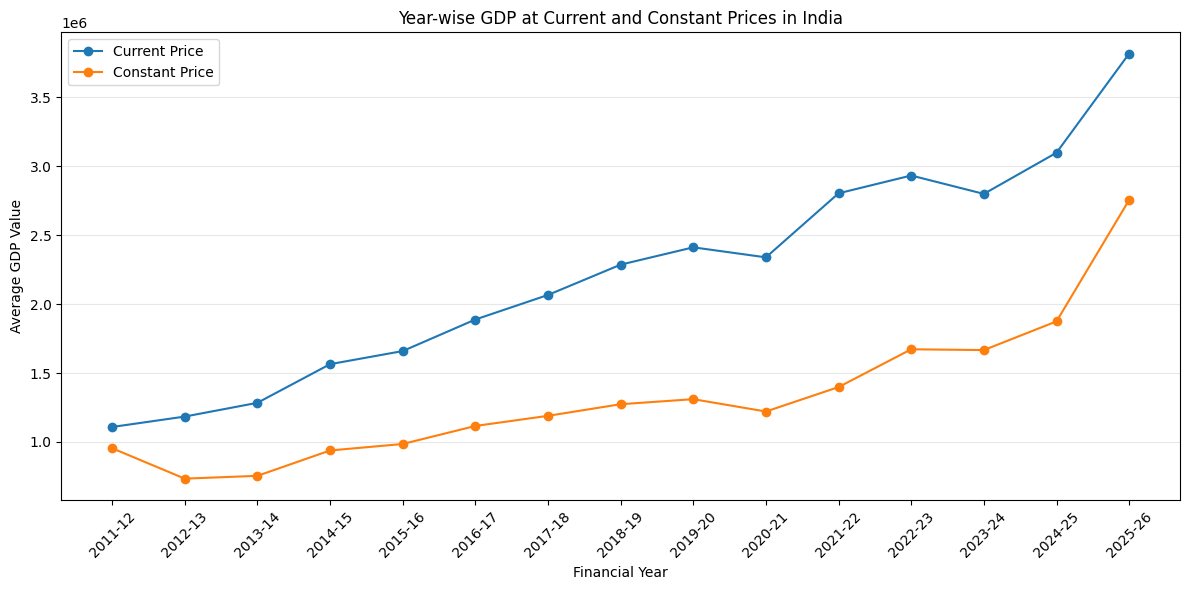

In [40]:
# year-wise gdp at current and constant price
plt.figure(figsize=(12, 6))

plt.plot(visual_data["Year"], visual_data["Current_Price"],
         marker="o", label="Current Price")

plt.plot(visual_data["Year"], visual_data["Constant_Price"],
         marker="o", label="Constant Price")

plt.title("Year-wise GDP at Current and Constant Prices in India")
plt.xlabel("Financial Year")
plt.ylabel("Average GDP Value")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# **Interpretation** — Year-wise GDP at Current and Constant Prices

*  GDP values at current prices are higher than those at constant prices throughout the period
* Both series show an overall increasing trend across the financial years.
*   Both measures show a dip around 2020–21, followed by an increase in subsequent years.
*   The highest displayed values occur in 2025–26 for both series.




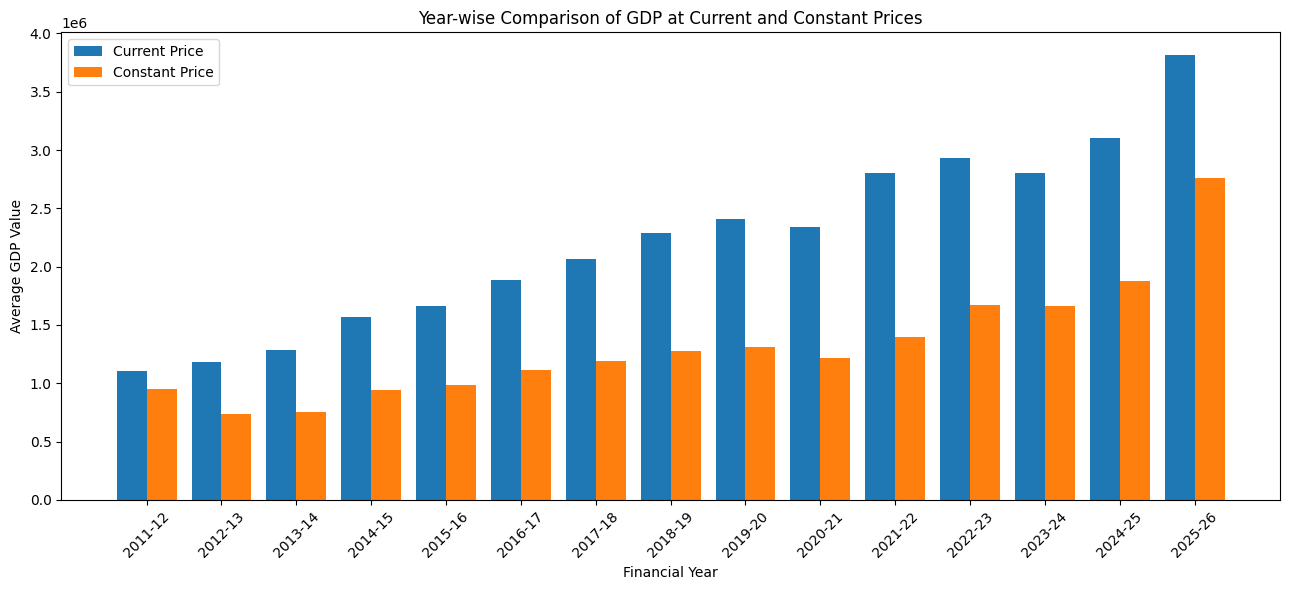

In [50]:
# Grouped chart of year wise Comparison at cuurent and constant prices
x = np.arange(len(visual_data))
width = 0.4

plt.figure(figsize=(13, 6))

plt.bar(
    x - width/2,
    visual_data["Current_Price"],
    width,
    label="Current Price"
)

plt.bar(
    x + width/2,
    visual_data["Constant_Price"],
    width,
    label="Constant Price"
)

plt.title("Year-wise Comparison of GDP at Current and Constant Prices")
plt.xlabel("Financial Year")
plt.ylabel("Average GDP Value")
plt.xticks(x, visual_data["Year"], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation – Year-wise Comparison of GDP at Current and Constant Prices

- **2011–12**: GDP averaged 1,108,641.10 at current prices and 954,304.49 at constant prices.
- **2015–16**: GDP increased to 1,659,528.23 at current prices and 985,170.21 at constant prices.
- **2020–21**: Current-price GDP decreased from 2,412,330.85 in 2019–20 to 2,339,654.89, while constant-price GDP decreased from 1,310,421.41 to 1,220,825.41.
- **2022–23**: GDP reached 2,933,583.21 at current prices and 1,672,463.52 at constant prices.
- **2023–24**: Both measures declined slightly, to 2,800,148.80 and 1,666,692.40, respectively.
- **2025–26**: The highest values in the displayed period were recorded, at 3,818,356.32 for current prices and 2,756,158.21 for constant prices.
- **Overall finding**: Current-price GDP remained higher than constant-price GDP in every financial year shown, and both measures generally increased over the period.

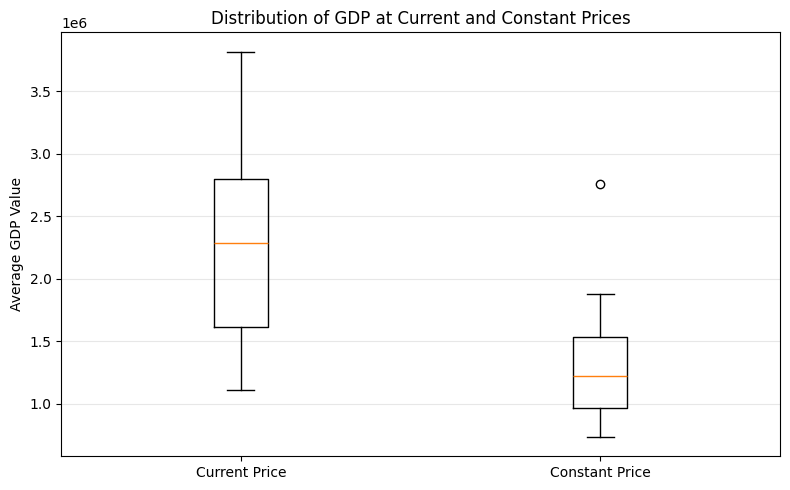

In [49]:
# distribution of gdp at current and costant prices
plt.figure(figsize=(8, 5))

plt.boxplot( [visual_data["Current_Price"],visual_data["Constant_Price"]],
    tick_labels=["Current Price", "Constant Price"])

plt.title("Distribution of GDP at Current and Constant Prices")
plt.ylabel("Average GDP Value")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation – Box Plot of GDP at Current and Constant Prices

* **Current Price:** The median GDP value is **2,286,646.99**, with a minimum of **1,108,641.10** and a maximum of **3,818,356.32**.
* **Constant Price:** The median GDP value is **1,222,825.49**, with a minimum of **733,691.06** and a maximum of **2,756,158.21**.
* **Comparison:** Current-price GDP has a higher median and a wider range of values than constant-price GDP.
* **Outlier:** The box plot shows an unusually high constant-price value, approximately **2,756,158.21**, compared with the other observations.







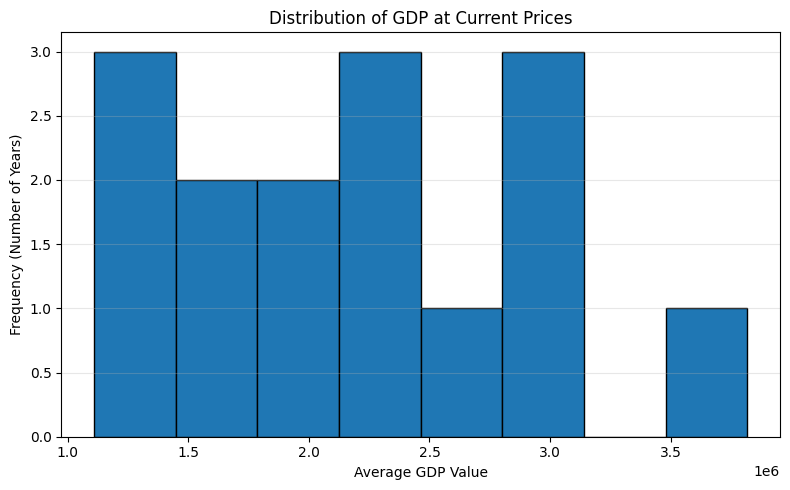

In [43]:
# distribution of gdp at current price
plt.figure(figsize=(8, 5))

plt.hist(visual_data["Current_Price"].dropna(),bins=8,edgecolor="black")

plt.title("Distribution of GDP at Current Prices")
plt.xlabel("Average GDP Value")
plt.ylabel("Frequency (Number of Years)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation – Distribution of GDP at Current Prices

* **Number of observations:** 15 financial-year records.
* **Minimum GDP value:** 1,108,641.10.
* **Maximum GDP value:** 3,818,356.32.
* **Mean GDP value:** 2,216,684.00, approximately.
* The histogram shows how the 15 GDP values are distributed across different value intervals. The values vary considerably, with one particularly high value near 3.82 million.



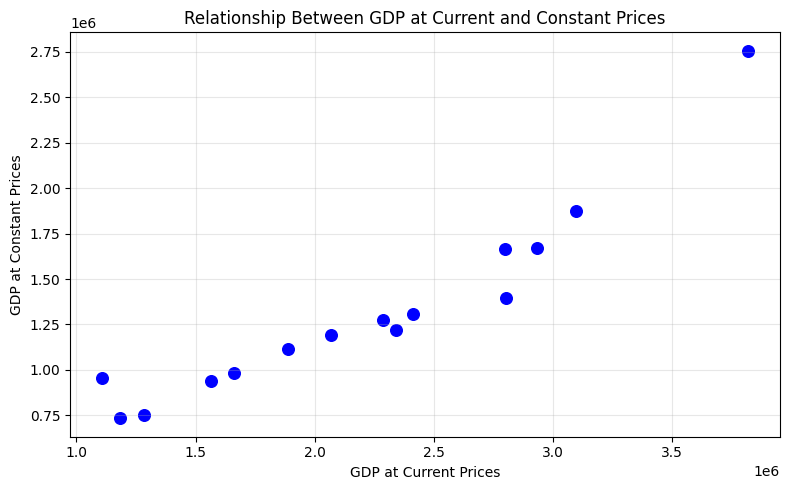

In [44]:
# Relationship between GDP at current and constant price
plt.figure(figsize=(8, 5))

plt.scatter(visual_data["Current_Price"],visual_data["Constant_Price"],color="blue",s=70)

plt.title("Relationship Between GDP at Current and Constant Prices")
plt.xlabel("GDP at Current Prices")
plt.ylabel("GDP at Constant Prices")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### **Interpretation – Relationship Between GDP at Current and Constant Prices**

* The scatter plot compares GDP at current prices and constant prices using 15 financial-year observations.
* Current-price GDP ranges from **1,108,641.10 to 3,818,356.32**, while constant-price GDP ranges from **733,691.06 to 2,756,158.21**.
* The correlation coefficient is **0.9379**, indicating a strong positive relationship between the two GDP measures.
* The upward pattern of the points supports this relationship: higher current-price GDP values generally correspond to higher constant-price GDP values.


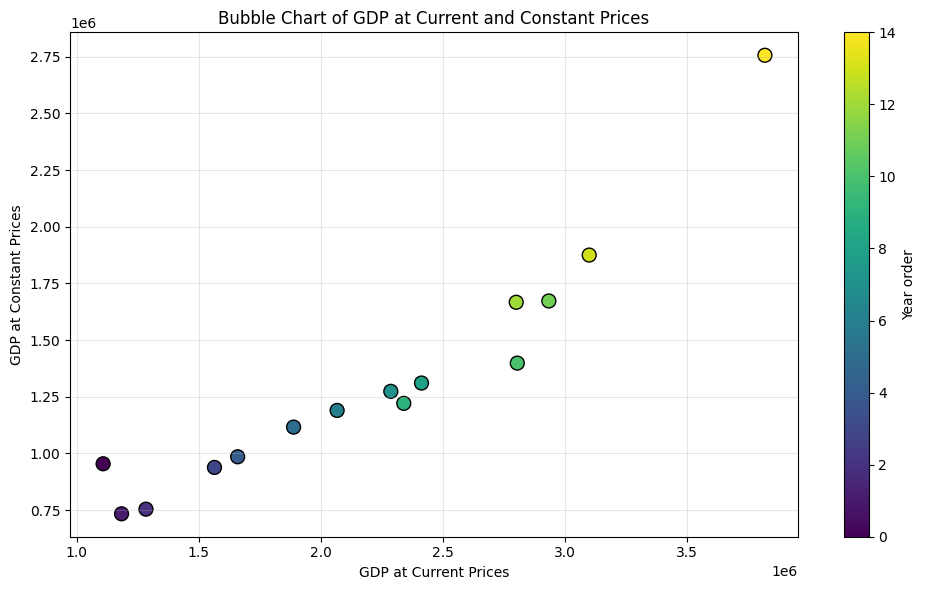

In [45]:
# bubble chart of gdp atcurrent and constant prices
plt.figure(figsize=(10, 6))
years = visual_data["Year"].astype(str)
scatter = plt.scatter(visual_data["Current_Price"], visual_data["Constant_Price"],
                      s=100,
                      c=range(len(visual_data)),
                      cmap="viridis",
                      edgecolor="black")

plt.colorbar(scatter, label="Year order")
plt.title("Bubble Chart of GDP at Current and Constant Prices")
plt.xlabel("GDP at Current Prices")
plt.ylabel("GDP at Constant Prices")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **Interpretation - Bubble Chart of GDP at Current and Constant Price**
* **Variables used:** Financial year, GDP at current prices, and GDP at constant prices.
* **Overall trend:** GDP values generally increased from 2011-12 to 2025-26, although some declines occurred in 2020-21 and 2023-24.
* **Minimum values:** Current prices-1,108,641.10; constant prices-733,691.06.
* **Maximum values:** Current prices-3,818,356.32; constant prices-2,756,15821.
* **Relationship:** The correlation coefficient is **0.9379**, indicating a strong positive relationship between the two GDP measures in these 15 observations.


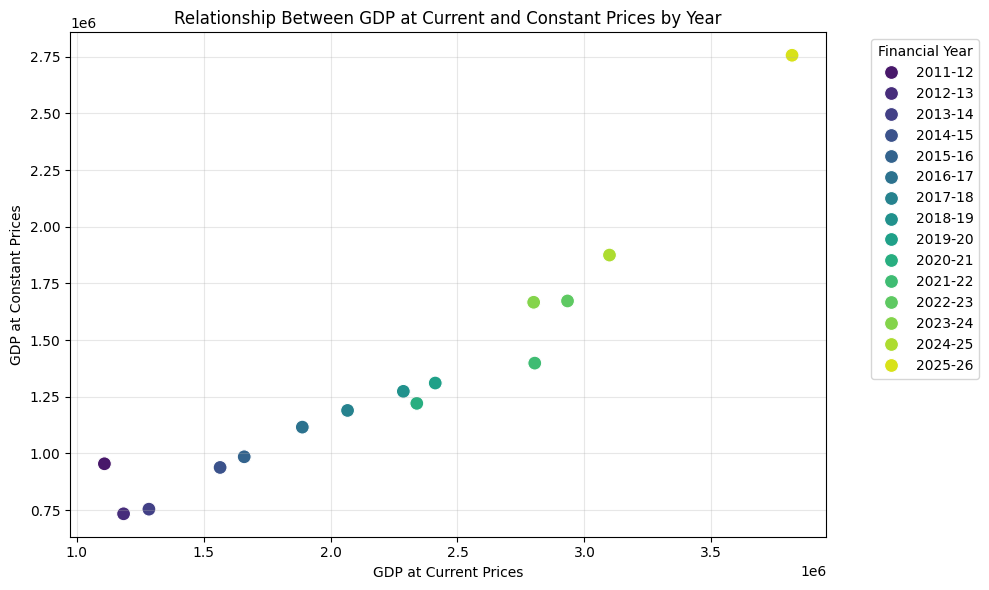

In [46]:
# Multivariate scatter plot: GDP values by financial year
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=visual_data,
    x="Current_Price",
    y="Constant_Price",
    hue="Year",
    palette="viridis",
    s=100)

plt.title("Relationship Between GDP at Current and Constant Prices by Year")
plt.xlabel("GDP at Current Prices")
plt.ylabel("GDP at Constant Prices")
plt.legend(title="Financial Year", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **Interpretation — Multivariate analysis**

* The chart compares GDP at current prices and constant prices across 15 financial years, from 2011–12 to 2025–26.
* A strong positive relationship is observed between the two measures, with a correlation coefficient of 0.9379.
* The highest values occur in 2025–26: current-price GDP is 3,818,356.32, and constant-price GDP is 2,756,158.21.
* The lowest values occur in 2011–12 for current prices (1,108,641.10) and 2013–14 for constant prices (733,691.06).

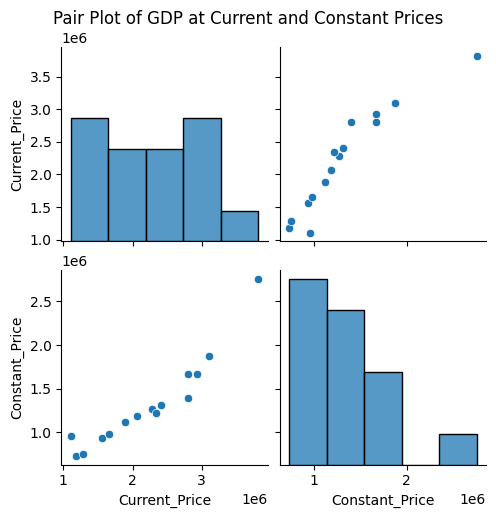

In [47]:
# Multivariate Pair Plot
pair_data = visual_data[
    ["Current_Price", "Constant_Price"]
].copy()

sns.pairplot(pair_data, diag_kind="hist")
plt.suptitle("Pair Plot of GDP at Current and Constant Prices", y=1.02)
plt.show()

### Interpretation – Pair Plot of GDP at Current and Constant Prices

* **Variables used:** Current Price and Constant Price GDP values across 15 financial years.
* **Positive relationship:** The scatter plots show that as current-price GDP increases, constant-price GDP generally increases too.
* **Current Price:** Values range from **1,108,641.10 to 3,818,356.32**.
* **Constant Price:** Values range from **733,691.06 to 2,756,158.21**.
* **Distribution:** The histograms on the diagonal show how the values are distributed. The scatter plots outside the diagonal show the relationship between the two variables.




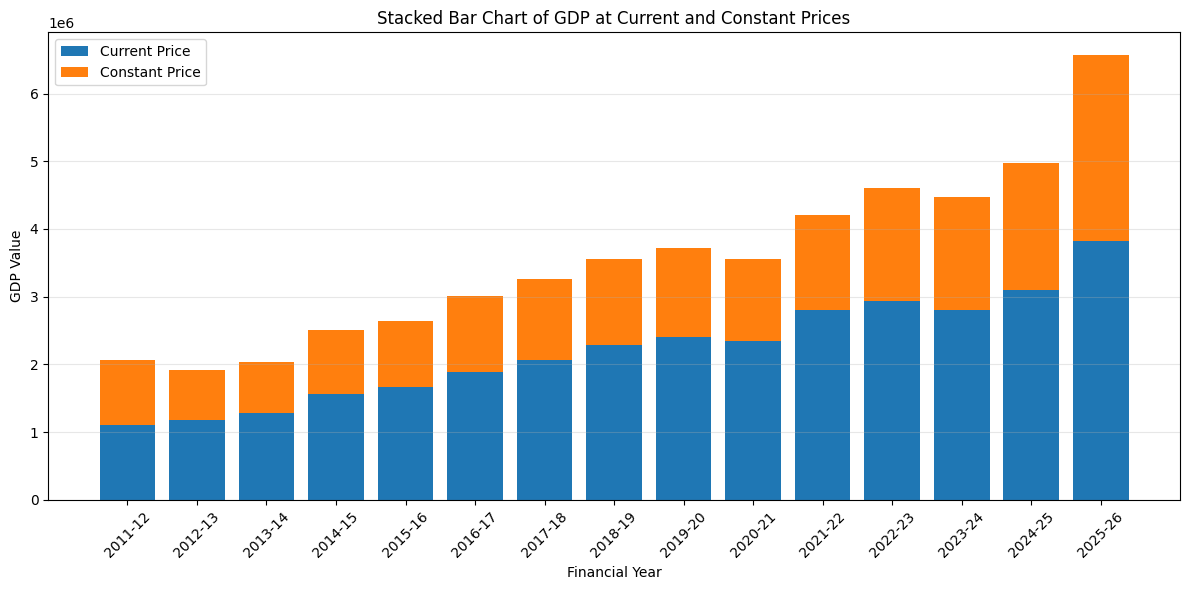

In [48]:
# Stacked BarChart of gdpat current and constant price
years = visual_data["Year"].astype(str)
current = visual_data["Current_Price"]
constant = visual_data["Constant_Price"]

plt.figure(figsize=(12, 6))

plt.bar(years, current, label="Current Price")
plt.bar(years, constant, bottom=current, label="Constant Price")

plt.title("Stacked Bar Chart of GDP at Current and Constant Prices")
plt.xlabel("Financial Year")
plt.ylabel("GDP Value")
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### **Interpretation – Stacked Bar Chart of GDP at Current and Constant Prices**

* **Variables used:** Current-price GDP and constant-price GDP across 15 financial years, from 2011–12 to 2025–26.
* **Overall trend:** Both measures generally increase over the period, with a decline in 2020–21 followed by recovery.
* **Highest values:** In 2025–26, current-price GDP is **3,818,356.32** and constant-price GDP is **2,756,158.21**. Their combined plotted height is approximately **6,574,514.53**.
* **Lowest values:** In 2011–12, current-price GDP is **1,108,641.10** and constant-price GDP is **954,304.49**. Their combined plotted height is approximately **2,062,945.59**.



## **Documentation,Insights & Presentation**

## **Summary of Findings**

The analysis of the National Accounts Statistics of India dataset produced the following major findings:

* **Dataset Quality:** Missing values were handled, and 15 duplicate records were removed to improve data quality.

* **Final Dataset:** The cleaned dataset contains 7,821 records and 16 columns.

* **GDP Trend:** GDP values at current and constant prices generally increased across the 15 financial years from 2011–12 to 2025–26.

* **Current and Constant Prices:** Current-price GDP values were higher than constant-price GDP values throughout the selected period.

* **Highest GDP Values:** In 2025–26, current-price GDP reached 3,818,356.32, while constant-price GDP reached 2,756,158.21.

* **Lowest GDP Values:** Current-price GDP recorded its lowest value of 1,108,641.10 in 2011–12, while constant-price GDP recorded its lowest value of 733,691.06 in 2012–13.

* **Statistical Relationship:** Pearson correlation analysis showed a strong positive relationship (r = 0.9379) between the two GDP measures across the 15 annual observations.

Overall, the findings indicate an increasing trend in both GDP measures and a strong positive association between current and constant time.


## Type of Analysis

**1. Descriptive Analysis**

Examined the structure and characteristics of the dataset using record counts, data types, summary statistics, mean, median, minimum and maximum values. This provided an overview of the GDP data.

**2. Data Quality Analysis**

Identified missing values, duplicate records, inconsistent entries and data types. Missing values were handled, and 15 duplicate records were removed to improve dataset reliability.

**3. Trend Analysis**

Analysed year-wise changes in GDP at current and constant prices across 15 financial years. The analysis identified an overall increasing trend, along with declines in certain years.

**4. Comparative Analysis**

Compared GDP values at current and constant prices using grouped bar charts and summary statistics. Current-price GDP was consistently higher than constant-price GDP.

**5. Distribution Analysis**

Used histograms and box plots to examine the distribution, spread, median, range and potential outliers of GDP values.

**6. Correlation Analysis**

Applied Pearson correlation to measure the relationship between current-price and constant-price GDP. The correlation coefficient of 0.9379 indicated a strong positive relationship.

**7. Multivariate Analysis**

Examined the relationship between multiple variables by considering current-price GDP, constant-price GDP and financial years together using colour-coded visualizations and pair plots.

These analytical methods helped transform the raw dataset into meaningful statistical findings.







## Recommendations / Decision Support

Based on the analysis, the following recommendations and decision-support observations are presented:

* **Economic Monitoring:** The year-wise GDP trends can help analysts monitor changes in India's economic performance over time.

* **Price Comparison:** Comparing current-price and constant-price GDP helps distinguish changes in GDP values from changes reflected after accounting for price variations.

* **Further Investigation:** Years showing declines in GDP values, particularly 2020–21 and 2023–24, can be examined further to understand the factors behind these changes.

* **Data Quality:** Regular validation, duplicate removal and proper handling of missing values should be maintained to improve the reliability of statistical analysis.

* **Statistical Monitoring:** Correlation analysis can help understand the relationship between GDP measures, while additional statistical methods can support deeper economic studies.

* **Evidence-Based Decisions:** The findings and visualizations can support researchers and analysts in identifying economic patterns and planning further investigations.

These recommendations provide useful analytical support for understanding GDP trends. The results are descriptive and should not be treated as proof of economic causes.



## Future Enhancement

The project can be extended in the following ways to improve its analytical scope and usefulness:

* **Longer Time Period:** Include additional historical GDP data to study long-term economic trends.

* **GDP Growth Rate Analysis:** Calculate year-on-year GDP growth rates to understand the rate of economic change.

* **Industry-wise Analysis:** Examine GDP contributions across different industries to identify major contributors to economic activity.

* **Predictive Analysis:** Apply suitable time-series forecasting techniques to estimate future GDP trends.

* **Advanced Statistical Analysis:** Use regression analysis and other statistical methods to explore relationships among economic indicators.

* **Interactive Dashboard:** Develop an interactive dashboard using Power BI to allow users to explore GDP trends and comparisons dynamically.

* **Additional Economic Indicators:** Include employment, inflation, investment and other economic indicators for a broader analysis.

These enhancements can expand the project from descriptive analysis into more advanced statistical analysis and economic forecasting.

